# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Include contributors names here!**

## Setup

*Install any packages here, define any functions if needed, and load data.*

In [9]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

# Feature Engineering
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA

In [22]:
# Load data  
df_Avg = pd.read_csv("avg_river_levels.csv")
df_Min = pd.read_csv("min_river_levels.csv")
df_Max = pd.read_csv("max_river_levels.csv")
df_Locs = pd.read_csv("monitoring_locations.csv",index_col="Observation_ID")
#df_Avg.head()
#df_Min.head()
#df_Max.head()
#df_Locs.head()

# check dates 
Dates = pd.to_datetime( df_Avg.columns[3:], format="%d/%m/%Y" )
print("Date col. ", len(Dates))
print("Days in the period:", (Dates.max() - Dates.min()).days + 1)
all_days = pd.date_range(Dates.min(), Dates.max(), freq="D")
print(all_days.difference(Dates))

Date col.  4379
Days in the period: 4387
DatetimeIndex(['2014-10-11', '2014-10-12', '2014-11-26', '2015-04-17',
               '2015-04-22', '2015-05-03', '2015-05-26', '2016-04-06'],
              dtype='datetime64[us]', freq=None)


In [23]:

def to_daily(df):
    #Takes data frame from one of the river level files
    #Returns the water levels wirth one row per day and one column per station
    
    levels= df.iloc[:, 3:].T
    levels.index = pd.to_datetime(levels.index, format="%d/%m/%Y")
    levels.columns = df["Observation_ID"]
    
    return levels


# Re-shap dates 
avg= to_daily(df_Avg)
lo= to_daily(df_Min)
hi= to_daily(df_Max)

# Avrage, minimum and maximum value in each file 
pd.DataFrame({"avg":[ avg.min().min(), avg.max().max() ], 
             "min":[ lo.min().min(), lo.max().max() ], 
             "max":[ hi.min().min(), hi.max().max()] },index=[ "smallest" , "largest" ])

#Combining raw values into ratios
def create_Features( avg,lo,hi):
    #Takes the daily avrage, minimum and maximum levels 
    #Returns one row of data frame features per station. Each feature is divided by the station's IQR or quantile
    #We don't want it to depend on the gauge or river size

    q05,q25,q50,q75,q95 =[avg.quantile(p) for p in [0.05,0.25,0.5,0.75, 0.95]]
    iqr= q75-q25
    change= avg.diff()   #day to day change

    Features= pd.DataFrame(index=avg.columns)
    Features["flash"]= change.abs().mean() / iqr
    Features["daily_range"]= ( hi - lo ).median() / iqr
    Features["qskew"]=( q95 + q05 - 2 * q50 ) / ( q95 - q05 )
    Features["p_rise"] =( change > 0 ).sum() / ( ( change > 0 ) | ( change < 0 )).sum()
    Features["acf1"]= avg.apply(lambda s: s.autocorr(lag=1))
    
    return Features

    

# Introduction

*This section should include a brief introduction to the task and the data (assume this is a report you are delivering to a professional body (e.g. Scottish Government)).*

*State which supervised learning question you are answering.*

*Briefly outline the approaches being used (for both the clustering and your chosen supervised learning task) and the conclusions that you are able to draw.*

# Exploratory Data Analysis and Feature Engineering

*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

**My notes**
-There are missing dates but the are all before 2017 so no need to change them? 
-Ploted the years of data each station has and most have 8-9 years. 
-Removed the 24 sea gauges, because they measure the tide not a river. 
-removed outliers based on IQR*20 because the water levels can be more than IQR*3. Removed 91 station-days at 23 stations
-Turned each station daily recored into 5 numbers that describe river behaviour. we divided by IQR (station normal range), because the measures are from different zero point. This point is diffrent accross rivers beacuse it depends on the river size. This allow results to be based on the river behaviour soly, and not based on its size.
-Feature acf1 was droped because it was highly correlated with flush. Heat map result showed -0.87

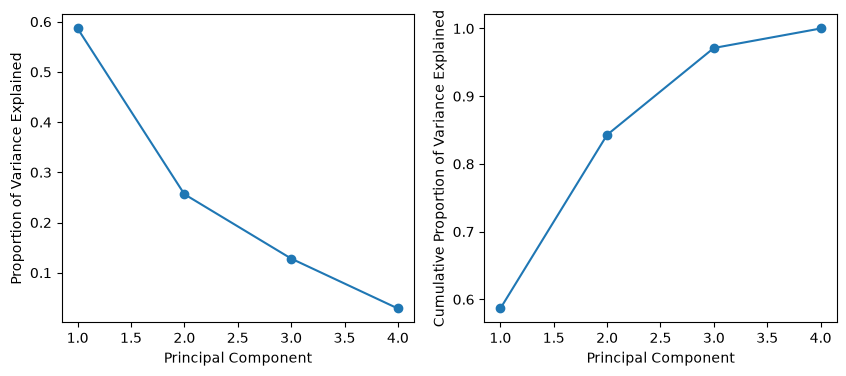

In [24]:


# Treat error codes "99999.999, -999999.999 and -99" as missing values
error_Code =(avg.abs() >=9999)|(lo.abs() >=9999)|(hi.abs() >=9999)|(lo == -99)

#print("There are {} station-days with error codes in {} stations".format(error_code.sum().sum(), error_code.any().sum()))
# Replace the error codes with missing values (NAN) 
#We remove the same amount of days from all data files so the calculations stay consistant
avg[error_Code]= np.nan
lo[error_Code]= np.nan
hi[error_Code]= np.nan

# Manage time window 
# check the days where the Maximum equals the Minimum 
sameMM= (hi == lo)   
share_same= ( sameMM.sum(axis=1).groupby(sameMM.index.year).sum()
            / hi.notna().sum(axis=1).groupby(hi.index.year).sum() )

# Keep data from this date only since the min mak doesn't effect our years much
avg = avg.loc["2017-01-01":]
lo = lo.loc["2017-01-01":]
hi = hi.loc["2017-01-01":]


#Get the station name with tide level to remove them (Sea data)
tidal_sites= df_Avg.loc[ df_Avg["Observation_ID"].str.contains("tidal-level"), "Station_Name" ] 
coastal= pd.Series(df_Avg["Station_Name"].isin(tidal_sites).values, index=df_Avg["Observation_ID"])


#Remove outliers where thier values lies way outside its IQR *20 to be realistic
#Tukey fence for each statoin
q1=avg.quantile(0.25)    
q3=avg.quantile(0.75)
iqr=q3-q1

scaled = (avg - avg.median()) / iqr
extreme = scaled.abs().max().sort_values(ascending=False).index[:6]

#Plot the 6 stations with most extreme values
# fig, ax = plt.subplots(1, 1, figsize=(10, 4))
# sns.boxplot(data=scaled[extreme].rename(columns=df_Locs["Observation_ID"]), orient="h", whis=20, ax=ax)
# ax.set_xscale("symlog")
# ax.set_xlabel("(level-median) / IQR")
# plt.show()

k = 20
outlier = avg.gt(q3 + k * iqr) | avg.lt(q1 - k * iqr)

avg[outlier] =np.nan
lo[outlier] =np.nan
hi[outlier] =np.nan

#Change each statin daily record into 5 numbers
Features = create_Features(avg, lo, hi)
Features.describe().round(3)

# If the group want to include in the report
#EDA: Histogram of the features  
# fig ,axes =plt.subplots(figsize=(15,3),ncols=5,nrows=1)
# axes =axes.flatten()

# for i, ax in enumerate(axes):
#     sns.histplot(data=Features.iloc[:, i], bins=30, ax=ax)
#     ax.set_title(Features.iloc[:, i].name)
#     ax.set_ylabel("")
#     ax.set_xlabel("")

# plt.tight_layout()
# plt.show()

# The Heatmap
# If the group want to include in the report
# plt.figure( figsize=(6, 5))
# sns.heatmap(Features.corr() ,annot=True , fmt='.2f', linewidths=2)
# plt.title("Correlation Heatmap")
# plt.show()
#Drop acf1 because its correlated with flash
X= Features.drop("acf1",axis=1)

#Yeo-Johnson transformation + standardisation
power_Transformer= PowerTransformer(method="yeo-johnson", standardize=True)
Z= power_Transformer.fit_transform(X)

# If the group want to include in the report
# fig,axes= plt.subplots(figsize=(12, 3), ncols=4,nrows=1)
# for i, ax in enumerate(axes):
#     sns.histplot(x=Z[:, i],bins=30,ax=ax)
#     ax.set_title(X.columns[i])
# plt.tight_layout()
# plt.show()

#PCA should be helpful for the clustering part
pca = PCA().fit(Z)
fig,ax= plt.subplots(1,2,figsize=(10,4))
ticks= np.arange(pca.n_components_) + 1
ax[0].plot(ticks,pca.explained_variance_ratio_, marker='o')
ax[0].set_xlabel('Principal Component')
ax[0].set_ylabel('Proportion of Variance Explained')
ax[1].plot(ticks, pca.explained_variance_ratio_.cumsum(), marker='o')
ax[1].set_xlabel('Principal Component')
ax[1].set_ylabel('Cumulative Proportion of Variance Explained')
plt.show()


# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

# Generative AI statement

ELM: 
How is pd.to_datetime used. 

# References

*Include a list of all references cited in the text.*

In [1]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Writing 29863 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 47131 bytes to project.pdf
